# MINGGU 13 — TUNING MODEL 1: BASELINE (TF-IDF + LOGISTIC REGRESSION)

**Mata Kuliah:** Data Science (Semester 5)  
**Proyek:** Analisis Klasifikasi Ujaran Kebencian pada Informasi Pemerintahan Indonesia di Media Sosial Menggunakan Machine Learning dan Deep Learning  
**PIC / Anggota 1:** Ardhana Syah Hidayat (244311037)  
**Kolaborator / Anggota 2:** Muhammad Adam Al-Kidri (244311050)  

---

### Tujuan Notebook:
1. Melakukan *Hyperparameter Tuning* terpadu pada *pipeline* `TfidfVectorizer` + `LogisticRegression` menggunakan **5-Fold Stratified Cross-Validation** hanya pada **Training Set** (`train.csv`).
2. Mencatat *Search Space*, *Best Parameters*, dan membandingkan performa Baseline **sebelum vs sesudah tuning** pada **Validation Set** (`val.csv`).
3. Melakukan optimasi *Decision Threshold* ($\tau$) pada Validation Set untuk menyeimbangkan **Macro F1-Score** dan **Precision Kelas 1** (*Hate Speech*, target $\ge 85\%$) guna mencegah sensor berlebih pada kritik wajar.
4. Menyimpan metrik hasil tuning ke `results/baseline_tuned_val_metrics.json` tanpa menyentuh `test.csv`.

In [1]:
import time
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.metrics import (
    classification_report, confusion_matrix, f1_score,
    precision_score, recall_score, roc_auc_score, average_precision_score
)

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120
SEED = 42

current_dir = Path.cwd()
root_dir = current_dir if (current_dir / 'data').exists() else current_dir.parent
data_dir = root_dir / 'data' / 'processed'
results_dir = root_dir / 'results'
results_dir.mkdir(parents=True, exist_ok=True)

train_df = pd.read_csv(data_dir / 'train.csv', keep_default_na=False)
val_df = pd.read_csv(data_dir / 'val.csv', keep_default_na=False)

X_train = train_df['text_clean_lexical']
y_train = train_df['HS'].values
X_val = val_df['text_clean_lexical']
y_val = val_df['HS'].values

print(f"Train Set : {len(train_df):,} baris | Val Set : {len(val_df):,} baris")

Train Set : 9,105 baris | Val Set : 1,951 baris


## 1. Evaluasi Baseline Awal (Sebelum Tuning)
Sebagai pembanding langsung, kita latih ulang konfigurasi awal Minggu 3 (`max_features=5000`, `ngram_range=(1,2)`, `C=1.0`, `class_weight='balanced'`) pada data yang sama.

In [2]:
base_pipe = Pipeline([
    ('tfidf', TfidfVectorizer(ngram_range=(1, 2), max_features=5000, min_df=2, sublinear_tf=True)),
    ('clf', LogisticRegression(C=1.0, class_weight='balanced', solver='lbfgs', max_iter=1000, random_state=SEED))
])
base_pipe.fit(X_train, y_train)
y_val_pred_base = base_pipe.predict(X_val)
y_val_prob_base = base_pipe.predict_proba(X_val)[:, 1]

base_metrics = {
    'Macro_F1': f1_score(y_val, y_val_pred_base, average='macro'),
    'Precision_HS': precision_score(y_val, y_val_pred_base),
    'Recall_HS': recall_score(y_val, y_val_pred_base),
    'ROC_AUC': roc_auc_score(y_val, y_val_prob_base),
    'PR_AUC': average_precision_score(y_val, y_val_prob_base),
}
print("Skor Baseline Awal (Validation Set):", {k: round(v, 4) for k, v in base_metrics.items()})

Skor Baseline Awal (Validation Set): {'Macro_F1': 0.8414, 'Precision_HS': 0.8167, 'Recall_HS': 0.8167, 'ROC_AUC': 0.9168, 'PR_AUC': 0.8794}


## 2. Hyperparameter Tuning (5-Fold Stratified GridSearchCV)
Seluruh pencarian dilakukan dalam *Pipeline* agar proses `TfidfVectorizer.fit()` terjadi terisolasi di dalam setiap *fold* pelatihan (*zero data leakage*):
* `tfidf__ngram_range`: `[(1, 1), (1, 2)]`
* `tfidf__max_features`: `[5000, 10000, 15000]`
* `clf__C`: `[0.5, 1.0, 2.0, 5.0]`
* `tfidf__min_df`: `2`, `clf__class_weight`: `'balanced'`

In [3]:
tune_pipe = Pipeline([
    ('tfidf', TfidfVectorizer(min_df=2, sublinear_tf=True)),
    ('clf', LogisticRegression(class_weight='balanced', solver='lbfgs', max_iter=1000, random_state=SEED))
])

param_grid = {
    'tfidf__ngram_range': [(1, 1), (1, 2)],
    'tfidf__max_features': [5000, 10000, 15000],
    'clf__C': [0.5, 1.0, 2.0, 5.0]
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
t0 = time.perf_counter()
grid = GridSearchCV(
    tune_pipe,
    param_grid=param_grid,
    scoring='f1_macro',
    cv=cv,
    n_jobs=-1,
    return_train_score=True
)
grid.fit(X_train, y_train)
elapsed = time.perf_counter() - t0

print(f"GridSearchCV selesai dalam {elapsed:.2f} detik ({len(param_grid['tfidf__ngram_range']) * len(param_grid['tfidf__max_features']) * len(param_grid['clf__C'])} kandidat x 5 folds)")
print(f"Best CV Macro F1 : {grid.best_score_:.4f}")
print(f"Best Parameters  : {grid.best_params_}")

GridSearchCV selesai dalam 72.61 detik (24 kandidat x 5 folds)
Best CV Macro F1 : 0.8323
Best Parameters  : {'clf__C': 2.0, 'tfidf__max_features': 10000, 'tfidf__ngram_range': (1, 2)}


## 3. Evaluasi Sebelum vs Sesudah Tuning (Validation Set)

In [4]:
best_model = grid.best_estimator_
y_val_pred_tuned = best_model.predict(X_val)
y_val_prob_tuned = best_model.predict_proba(X_val)[:, 1]

# Cek Train score untuk memantau overfitting
y_train_pred_tuned = best_model.predict(X_train)
train_macro_f1 = f1_score(y_train, y_train_pred_tuned, average='macro')

tuned_metrics = {
    'Macro_F1': f1_score(y_val, y_val_pred_tuned, average='macro'),
    'Precision_HS': precision_score(y_val, y_val_pred_tuned),
    'Recall_HS': recall_score(y_val, y_val_pred_tuned),
    'ROC_AUC': roc_auc_score(y_val, y_val_prob_tuned),
    'PR_AUC': average_precision_score(y_val, y_val_prob_tuned),
}

comp_df = pd.DataFrame({
    'Sebelum Tuning (Minggu 3)': base_metrics,
    'Sesudah Tuning (Minggu 13)': tuned_metrics,
})
comp_df['Selisih (Delta)'] = comp_df['Sesudah Tuning (Minggu 13)'] - comp_df['Sebelum Tuning (Minggu 3)']
print(f"Train Macro F1 (Best Model): {train_macro_f1:.4f} vs Val Macro F1: {tuned_metrics['Macro_F1']:.4f} (Gap: {train_macro_f1 - tuned_metrics['Macro_F1']:.4f})")
display(comp_df.round(4))

print("\nClassification Report (Tuned Baseline pada Validation Set):")
print(classification_report(y_val, y_val_pred_tuned, target_names=['Non-HS (0)', 'Hate Speech (1)'], digits=4))

Train Macro F1 (Best Model): 0.9301 vs Val Macro F1: 0.8428 (Gap: 0.0873)


,Sebelum Tuning (Minggu 3),Sesudah Tuning (Minggu 13),Selisih (Delta)
Macro_F1,0.8414,0.8428,0.0014
Precision_HS,0.8167,0.8119,-0.0048
Recall_HS,0.8167,0.8277,0.0109
ROC_AUC,0.9168,0.9207,0.0039
PR_AUC,0.8794,0.8842,0.0049



Classification Report (Tuned Baseline pada Validation Set):
                 precision    recall  f1-score   support

     Non-HS (0)     0.8722    0.8598    0.8660      1127
Hate Speech (1)     0.8119    0.8277    0.8197       824

       accuracy                         0.8462      1951
      macro avg     0.8420    0.8437    0.8428      1951
   weighted avg     0.8467    0.8462    0.8464      1951



## 4. Optimasi Decision Threshold ($\tau$) pada Validation Set
Sesuai prinsip etika SDG 16 (`CONTEXT.md`), **Precision Kelas 1** ditargetkan $\ge 85\%$ untuk mencegah kritik kebijakan yang sah salah dilabeli sebagai ujaran kebencian (*False Positive*). Kita uji beberapa nilai ambang batas probabilitas pada Validation Set.

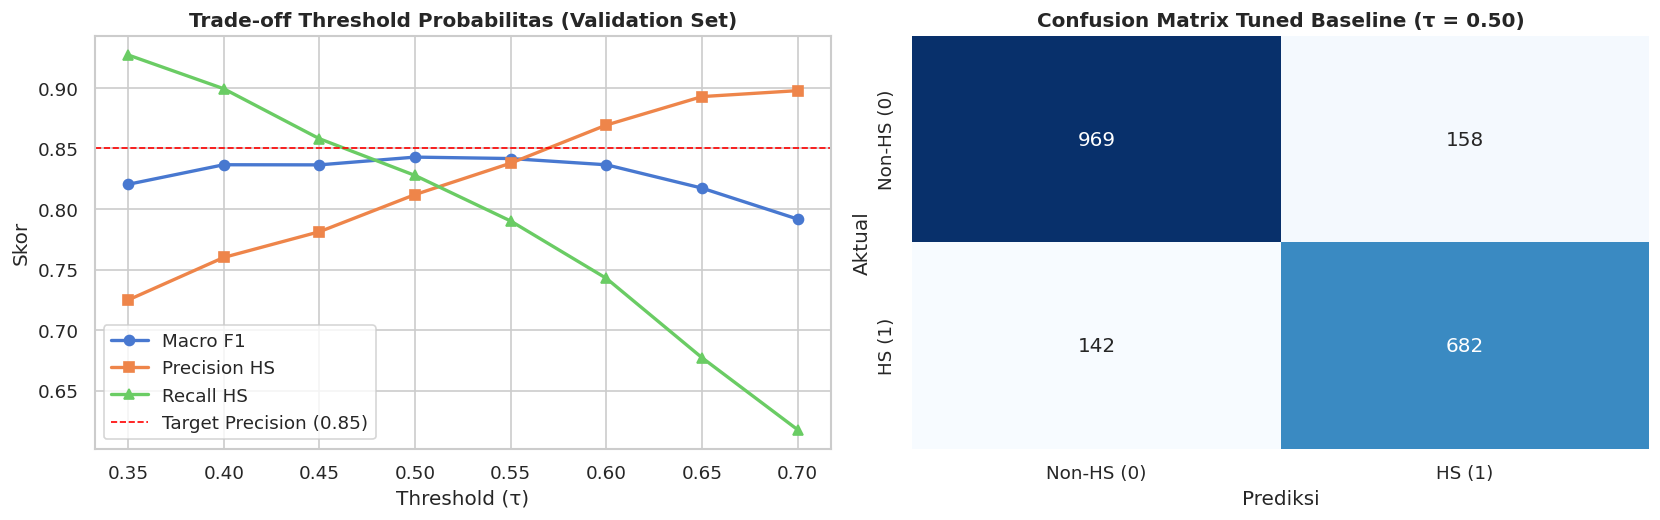

,Threshold,Macro_F1,Precision_HS,Recall_HS
0,0.35,0.8204,0.7249,0.9272
1,0.40,0.8365,0.7600,0.8993
2,0.45,0.8364,0.7812,0.8580
3,0.50,0.8428,0.8119,0.8277
4,0.55,0.8416,0.8378,0.7900
5,0.60,0.8365,0.8693,0.7427
6,0.65,0.8172,0.8928,0.6772
7,0.70,0.7917,0.8977,0.6177


In [5]:
thresholds = np.arange(0.35, 0.71, 0.05)
thr_rows = []
for thr in thresholds:
    preds = (y_val_prob_tuned >= thr).astype(int)
    thr_rows.append({
        'Threshold': round(float(thr), 2),
        'Macro_F1': f1_score(y_val, preds, average='macro'),
        'Precision_HS': precision_score(y_val, preds),
        'Recall_HS': recall_score(y_val, preds),
    })

thr_df = pd.DataFrame(thr_rows)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(thr_df['Threshold'], thr_df['Macro_F1'], marker='o', lw=2, label='Macro F1')
axes[0].plot(thr_df['Threshold'], thr_df['Precision_HS'], marker='s', lw=2, label='Precision HS')
axes[0].plot(thr_df['Threshold'], thr_df['Recall_HS'], marker='^', lw=2, label='Recall HS')
axes[0].axhline(0.85, color='red', linestyle='--', lw=1, label='Target Precision (0.85)')
axes[0].set_title('Trade-off Threshold Probabilitas (Validation Set)', fontweight='bold')
axes[0].set_xlabel('Threshold (τ)')
axes[0].set_ylabel('Skor')
axes[0].legend(loc='lower left')

cm = confusion_matrix(y_val, y_val_pred_tuned)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[1],
            xticklabels=['Non-HS (0)', 'HS (1)'], yticklabels=['Non-HS (0)', 'HS (1)'], cbar=False)
axes[1].set_title('Confusion Matrix Tuned Baseline (τ = 0.50)', fontweight='bold')
axes[1].set_xlabel('Prediksi')
axes[1].set_ylabel('Aktual')

plt.tight_layout()
plt.show()

display(thr_df.round(4))

In [6]:
# Simpan ringkasan metrik tuned baseline
out_payload = {
    'model_name': 'Baseline Tuned: Logistic Regression + TF-IDF',
    'best_params': {k: (list(v) if isinstance(v, tuple) else v) for k, v in grid.best_params_.items()},
    'cv_macro_f1': float(round(grid.best_score_, 4)),
    'train_macro_f1': float(round(train_macro_f1, 4)),
    'val_samples': int(len(val_df)),
    'macro_f1': float(round(tuned_metrics['Macro_F1'], 4)),
    'precision_hs': float(round(tuned_metrics['Precision_HS'], 4)),
    'recall_hs': float(round(tuned_metrics['Recall_HS'], 4)),
    'roc_auc': float(round(tuned_metrics['ROC_AUC'], 4)),
    'pr_auc': float(round(tuned_metrics['PR_AUC'], 4)),
    'confusion_matrix': {'tn': int(cm[0, 0]), 'fp': int(cm[0, 1]), 'fn': int(cm[1, 0]), 'tp': int(cm[1, 1])}
}
out_path = results_dir / 'baseline_tuned_val_metrics.json'
with open(out_path, 'w', encoding='utf-8') as f:
    json.dump(out_payload, f, indent=4)

print(f"Ringkasan metrik tuned baseline disimpan ke: {out_path}")

Ringkasan metrik tuned baseline disimpan ke: D:\TUGAS SEMESTER 5\DATA SCIENCE\id-gov-hatespeech-classification\results\baseline_tuned_val_metrics.json
